# EDA on the VM: channels, ball gaps, long-gap samples

**Run this notebook on your VM account.** Once it has run, its outputs contain competition data into a eda_out folder in your account ~/.

- if a copy with outputs ever has to move, clear it first:
  `jupyter nbconvert --clear-output --inplace eda_vm.ipynb`.

The script commands are **comments**. Run them in a VM terminal (or remove the `#` to run them
from here with `!`). The cells below each command only read what the scripts wrote under
`EDA_OUT` (default `~/eda_out`) and plot it.

Data paths come from `games.asset_paths()`, which honours `MTAH_DATA_DIR`. The public repo comes
from `MTAH_PUBLIC_REPO` (default `~/more-than-a-hack-2027`). Set both in the shell that starts
Jupyter; a kernel started some other way may not see your `~/.bashrc` exports.

In [1]:
import os
import sys
import socket

print("Host:", socket.gethostname())
print("Python:", sys.executable)
print("Working directory:", os.getcwd())

Host: mtah-data
Python: /home/robli-macbook-air-2026/more-than-a-hack-2027/.venv/bin/python3
Working directory: /home/robli-macbook-air-2026


In [2]:
import os
import sys
from pathlib import Path

PUBLIC_REPO = Path(os.environ.get("MTAH_PUBLIC_REPO", Path.home() / "more-than-a-hack-2027"))
EDA_OUT = Path(os.environ.get("EDA_OUT", Path.home() / "eda_out"))
os.environ["MTAH_PUBLIC_REPO"] = str(PUBLIC_REPO)   # for the commented ! commands

sys.path.insert(0, str(PUBLIC_REPO))
import games  # noqa: E402

print("public repo :", PUBLIC_REPO)
print("MTAH_DATA_DIR:", os.environ.get("MTAH_DATA_DIR", "(not set: games.py default)"))
print("EDA_OUT     :", EDA_OUT)
for name, path in games.asset_paths().items():
    print("  {:<14} {}".format(name, "ok" if Path(path).is_file() else "MISSING"))
print("graded blocks:", games.half_video_blocks("BAR-ATH"))

public repo : /home/robli-macbook-air-2026/more-than-a-hack-2027
MTAH_DATA_DIR: /srv/mtah/data
EDA_OUT     : /home/robli-macbook-air-2026/eda_out
  video          ok
  atd_meta       ok
  atd_raw        ok
  homography     ok
  smart_tagging  ok
graded blocks: [(1, 11185, 90651), (2, 110808, 190197)]


In [3]:
%matplotlib inline
import  matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BINS = ["<0.5s", "0.5-2s", "2-5s", ">=5s"]
SCOPES = ["overall", "half 1", "half 2"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def load_summary(folder):
    """ball_gaps_summary.csv from EDA_OUT/folder, or None."""
    path = EDA_OUT / folder / "ball_gaps_summary.csv"
    if not path.is_file():
        print("not found:", path)
        return None
    df = pd.read_csv(path, keep_default_na=False, dtype=str)
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    return df


def get(df, analysis, scope, bin_, metric):
    sel = df[(df.analysis == analysis) & (df.scope == scope) & (df.bin == bin_) &
             (df.metric == metric)]["value"]
    return float(sel.iloc[0]) if len(sel) else np.nan

## 1. `check_channels.py`: what the ATD metadata declares

Is there a ball-status or ball-owner channel, and how is each frame laid out?

In [ ]:
# cd more-than-a-hack
# PYTHONPATH="$PWD" python eda/check_channels.py "$HOME/eda_out/channels"
# PYTHONPATH="$PWD" python eda/check_channels.py "$HOME/eda_out/channels_broadcast" --source broadcast

== channels ==
sensor channels (3): position/x (normalized), position/y (normalized), speed/s (kph)
data format specs: 1
  spec 1: frames 1..199319, separator ':'
    1. string register: frameCount
    2. players: 46 slots x [x, y, speed]
    3. ball: [ball_x, ball_y, ball_s]
ball-status / ball-owner channel: NONE declared (only positions/speeds; dead ball and owner must be inferred)


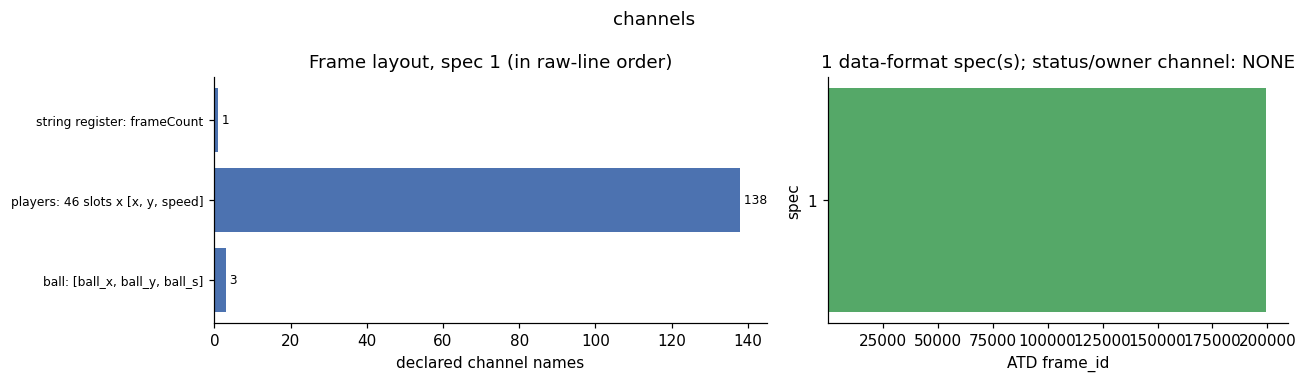

== channels_broadcast ==
sensor channels (3): position/x (normalized), position/y (normalized), speed/s (kph)
data format specs: 1
  spec 1: frames 1..164488, separator ':'
    1. string register: frameCount
    2. players: 51 slots x [x, y, speed]
    3. ball: [ball_x, ball_y, ball_s]
ball-status / ball-owner channel: NONE declared (only positions/speeds; dead ball and owner must be inferred)


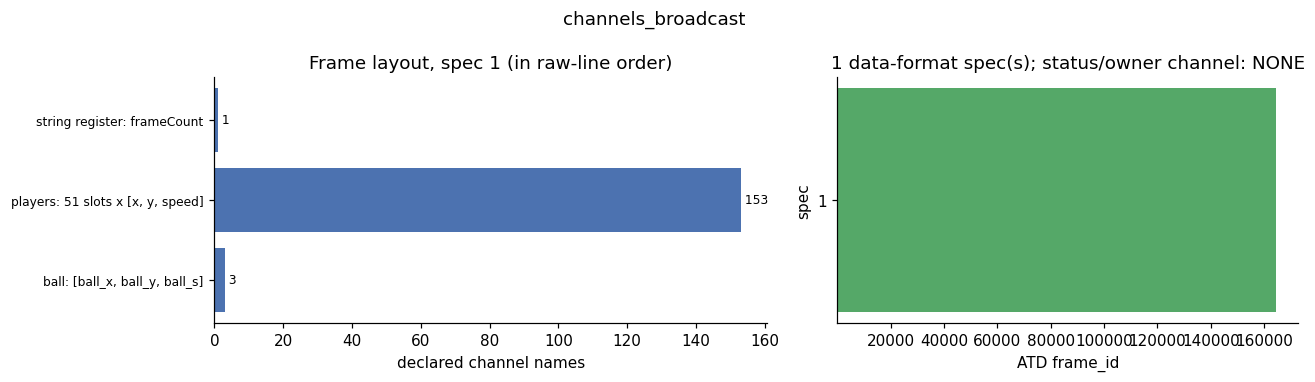

In [4]:
def parse_channels(path):
    """(summary text, [(spec, first, last)], {spec: [(block label, n names)]})."""
    summary, _, full = path.read_text().partition("\n\n")
    specs, blocks, spec = [], {}, None
    for line in full.splitlines():
        if line.startswith("# spec "):
            spec = int(line.split()[2].rstrip(":"))
            first, last = line.split("frames ")[1].split("..")
            specs.append((spec, first, last))
            blocks[spec] = []
        elif spec is None:
            continue
        elif line.startswith("## block"):
            blocks[spec].append([line.split(":", 1)[1].strip(), 0])
        elif line.strip() and blocks[spec]:
            blocks[spec][-1][1] += 1
    return summary, specs, blocks


for folder in ["channels", "channels_broadcast"]:
    path = EDA_OUT / folder / "channels.txt"
    if not path.is_file():
        print("not found:", path)
        continue
    summary, specs, blocks = parse_channels(path)
    print("==", folder, "==")
    print(summary)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5),
                                   gridspec_kw={"width_ratios": [1.2, 1]})
    labels = [b[0] if len(b[0]) <= 45 else b[0][:42] + "..." for b in blocks[specs[0][0]]]
    counts = [b[1] for b in blocks[specs[0][0]]]
    ax1.barh(range(len(counts)), counts, color="#4C72B0")
    ax1.set_yticks(range(len(counts)), labels, fontsize=8)
    ax1.invert_yaxis()
    ax1.set_xlabel("declared channel names")
    ax1.set_title("Frame layout, spec 1 (in raw-line order)")
    for i, c in enumerate(counts):
        ax1.text(c, i, " " + str(c), va="center", fontsize=8)

    for spec, first, last in specs:
        try:
            a, b = int(first), int(last)
        except ValueError:
            continue
        ax2.barh(spec, b - a + 1, left=a, color="#55A868")
    ax2.set_yticks([s for s, _, _ in specs])
    ax2.invert_yaxis()
    ax2.set_xlabel("ATD frame_id")
    ax2.set_ylabel("spec")
    status = "status/owner channel: " + ("NONE" if "NONE declared" in summary else "candidates found")
    ax2.set_title("{} data-format spec(s); {}".format(len(specs), status))
    fig.suptitle(folder)
    fig.tight_layout()
    plt.show()

## 2. `ball_gaps.py`: where the ball goes missing, and what happens across a gap

The main run, plus two sensitivity runs (set-piece tolerance of ±1 s, flip distance cap of 5 m).

In [ ]:
# PYTHONPATH="$PWD" python eda/ball_gaps.py "$HOME/eda_out/ball_gaps"

# PYTHONPATH="$PWD" python eda/ball_gaps.py "$HOME/eda_out/ball_gaps_tol1s" --tag-tolerance 1

# PYTHONPATH="$PWD" python eda/ball_gaps.py "$HOME/eda_out/ball_gaps_maxdist5" --flip-max-dist 5

In [5]:
RUNS = {"main": "ball_gaps", "tag ±1 s": "ball_gaps_tol1s", "flip ≤ 5 m": "ball_gaps_maxdist5"}
summaries = {name: load_summary(folder) for name, folder in RUNS.items()}
bg_main = summaries["main"]

### (a) Gap lengths: many short gaps, or a few long ones holding most missing frames?

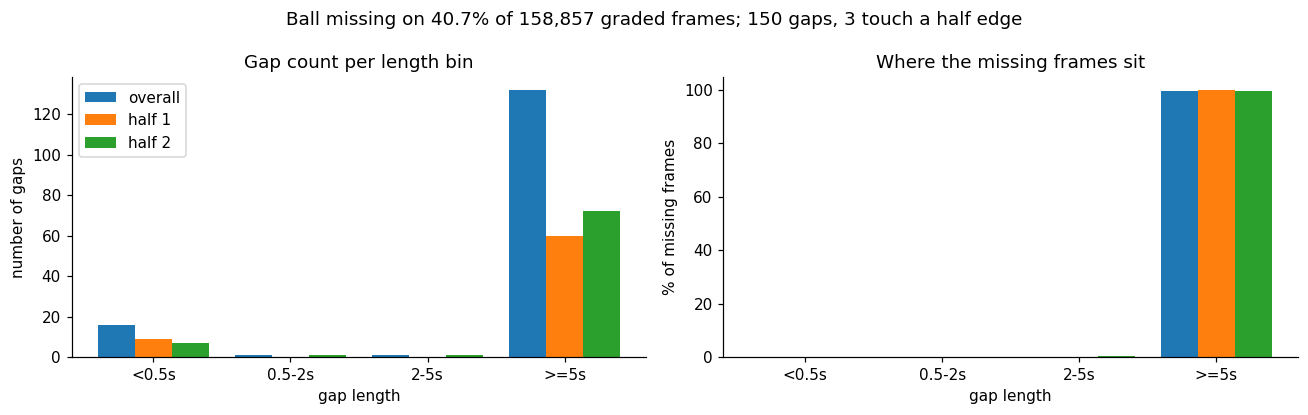

In [6]:
df = bg_main
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(BINS))
w = 0.27
for i, scope in enumerate(SCOPES):
    n = [get(df, "gap_length", scope, b, "n_gaps") for b in BINS]
    share = [get(df, "gap_length", scope, b, "share_of_missing_frames") for b in BINS]
    ax1.bar(x + (i - 1) * w, n, w, label=scope)
    ax2.bar(x + (i - 1) * w, share, w, label=scope)
for ax, ylab in ((ax1, "number of gaps"), (ax2, "% of missing frames")):
    ax.set_xticks(x, BINS)
    ax.set_xlabel("gap length")
    ax.set_ylabel(ylab)
ax1.legend()
ax1.set_title("Gap count per length bin")
ax2.set_title("Where the missing frames sit")
fig.suptitle("Ball missing on {:.1f}% of {:,.0f} graded frames; {:.0f} gaps, {:.0f} touch a "
             "half edge".format(get(df, "gap_length", "overall", "all", "missing_share_of_graded"),
                                get(df, "gap_length", "overall", "all", "graded_frames"),
                                get(df, "gap_length", "overall", "all", "n_gaps"),
                                get(df, "gap_length", "overall", "all", "edge_gaps")))
fig.tight_layout()
plt.show()

### (b) + (e) Long gaps vs SET PIECES: is the real overlap above chance?

Dot = real share of gaps overlapping a SET PIECES tag. Bar = null p5–p95 from circularly shifted
tags, with a tick at the null mean. Real above the band supports "long gap = stoppage".

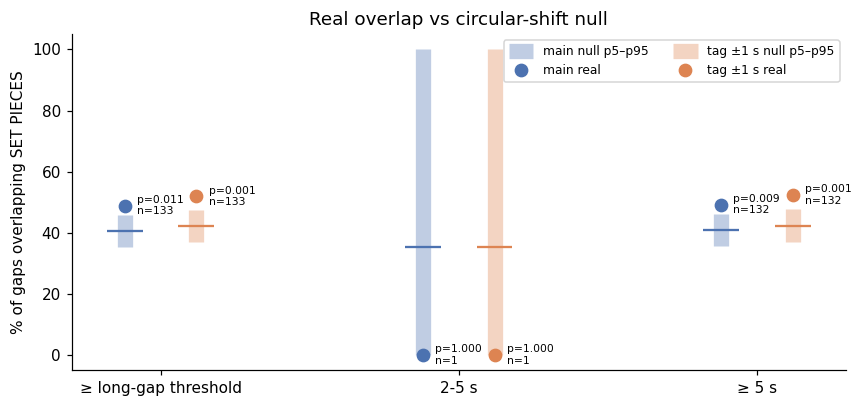

In [7]:
labels = [">=long", "2-5s", ">=5s"]
fig, ax = plt.subplots(figsize=(8, 3.8))
plotted = False
for k, (name, off) in enumerate((("main", -0.12), ("tag ±1 s", 0.12))):
    df = summaries[name]
    if df is None or not (df.analysis == "set_pieces_null").any():
        print(name, ": set-piece null not in the summary (no Smart Tagging file, or skipped)")
        continue
    plotted = True
    color = ["#4C72B0", "#DD8452"][k]
    for i, lab in enumerate(labels):
        lo, hi = (get(df, "set_pieces_null", "overall", lab, m) for m in ("null_p5", "null_p95"))
        mean = get(df, "set_pieces_null", "overall", lab, "null_mean")
        real = get(df, "set_pieces_null", "overall", lab, "real_share")
        p = get(df, "set_pieces_null", "overall", lab, "p_emp")
        n = get(df, "set_pieces_null", "overall", lab, "n_gaps")
        if np.isnan(real):
            continue
        ax.vlines(i + off, lo, hi, color=color, alpha=0.35, lw=10,
                  label=name + " null p5–p95" if i == 0 else None)
        ax.hlines(mean, i + off - 0.06, i + off + 0.06, color=color)
        ax.plot(i + off, real, "o", color=color, ms=8, label=name + " real" if i == 0 else None)
        ax.annotate("p={:.3f}\nn={:.0f}".format(p, n), (i + off, real), xytext=(8, 0),
                    textcoords="offset points", fontsize=7, va="center")
if plotted:
    ax.set_xticks(range(len(labels)), ["≥ long-gap threshold", "2-5 s", "≥ 5 s"])
    ax.set_ylabel("% of gaps overlapping SET PIECES")
    ax.set_title("Real overlap vs circular-shift null")
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    plt.show()
else:
    plt.close(fig)

### (c) Crowding: is the ball lost in contested play?

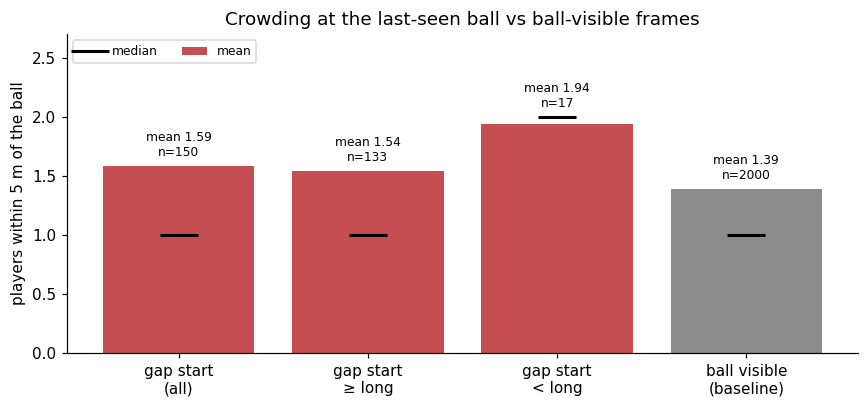

In [8]:
df = bg_main
groups = [("gap start\n(all)", "gap_start_all"), ("gap start\n≥ long", "gap_start_long"),
          ("gap start\n< long", "gap_start_short"), ("ball visible\n(baseline)", "visible")]
means = [get(df, "crowding", s, "", "mean") for _, s in groups]
medians = [get(df, "crowding", s, "", "median") for _, s in groups]
ns = [get(df, "crowding", s, "", "n") for _, s in groups]
radius = get(df, "params", "all", "", "radius")

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#C44E52"] * 3 + ["#8C8C8C"]
ax.bar(range(len(groups)), means, color=colors, label="mean")
ax.plot(range(len(groups)), medians, "k_", ms=25, mew=2, label="median")
top = np.nanmax(means + medians)
for i, (m, med, n) in enumerate(zip(means, medians, ns)):
    ax.text(i, np.nanmax([m, med]) + 0.03 * top, "mean {:.2f}\nn={:.0f}".format(m, n),
            ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, top * 1.35)
ax.set_xticks(range(len(groups)), [g for g, _ in groups])
ax.set_ylabel("players within {:g} m of the ball".format(radius))
ax.set_title("Crowding at the last-seen ball vs ball-visible frames")
ax.legend(loc="upper left", ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

### (d) Flips: does the nearest team change across a gap more than it would anyway?

Bars = flip rate across gaps. Grey = reference rate on ball-visible frame pairs the same distance
apart. Above each bar: flips / evaluable gaps.

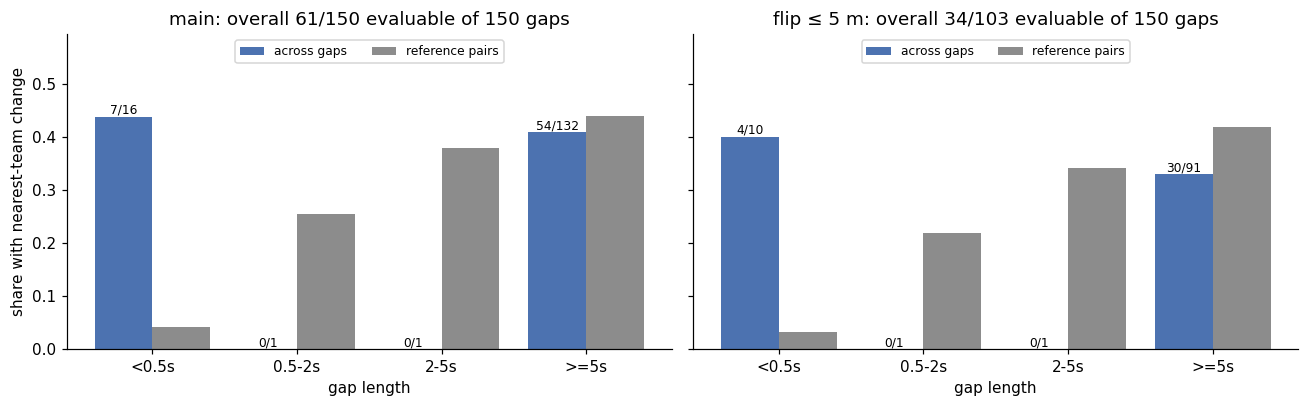

not evaluable (main): no_last_seen 0, no_reappearance 0, no_player 0, too_far 0


In [9]:
panels = [(n, d) for n, d in (("main", summaries["main"]), ("flip ≤ 5 m", summaries["flip ≤ 5 m"]))
          if d is not None and (d.analysis == "flip").any()]
if not panels:
    print("no flip rows (run without --meta?)")
else:
    fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 3.8), sharey=True,
                             squeeze=False)
    x = np.arange(len(BINS))
    for ax, (name, df) in zip(axes[0], panels):
        rate = [get(df, "flip", "overall", b, "flip_rate") for b in BINS]
        ref = [get(df, "flip", "overall", b, "ref_flip_rate") for b in BINS]
        ax.bar(x - 0.2, rate, 0.4, color="#4C72B0", label="across gaps")
        ax.bar(x + 0.2, ref, 0.4, color="#8C8C8C", label="reference pairs")
        for i, b in enumerate(BINS):
            k = get(df, "flip", "overall", b, "n_flip")
            n = get(df, "flip", "overall", b, "n_evaluable")
            ax.text(i - 0.2, 0 if np.isnan(rate[i]) else rate[i], "{:.0f}/{:.0f}".format(k, n),
                    ha="center", va="bottom", fontsize=8)
        allc = [get(df, "flip", "overall", "all", m) for m in ("n_flip", "n_evaluable", "n_gaps")]
        ax.set_xticks(x, BINS)
        ax.set_xlabel("gap length")
        ax.set_title("{}: overall {:.0f}/{:.0f} evaluable of {:.0f} gaps".format(name, *allc))
        ax.legend(fontsize=8, loc="upper center", ncol=2)
    top = max(np.nanmax([get(d, "flip", "overall", b, m) for b in BINS
                         for m in ("flip_rate", "ref_flip_rate")] + [0.05]) for _, d in panels)
    axes[0][0].set_ylim(0, top * 1.35)
    axes[0][0].set_ylabel("share with nearest-team change")
    fig.tight_layout()
    plt.show()

    df = panels[0][1]
    reasons = ["no_last_seen", "no_reappearance", "no_player", "too_far"]
    counts = {r: get(df, "flip", "overall", "all", "not_eval_" + r) for r in reasons}
    print("not evaluable ({}):".format(panels[0][0]),
          ", ".join("{} {:.0f}".format(r, c) for r, c in counts.items()))

## 3. `sample_long_gaps.py`: gaps to watch by hand

Five length strata, half-open in seconds: [0, 5), [5, 10), [10, 20), [20, 35), [35, ∞).
Each file holds up to 8 gaps, spread over both halves, excluding the public GT window and the
second-half frames before kickoff. These tables are **frame-indexed**: fill in `category` and
`notes` while watching, and keep the files on the VM.

In [ ]:
# PYTHONPATH="$PWD" python eda/sample_long_gaps.py "$HOME/eda_out/long_gaps" --min-s 0 --max-s 5 --csv-name gap_00_05_sample.csv

# PYTHONPATH="$PWD" python eda/sample_long_gaps.py "$HOME/eda_out/long_gaps" --min-s 5 --max-s 10 --csv-name gap_05_10_sample.csv

# PYTHONPATH="$PWD" python eda/sample_long_gaps.py "$HOME/eda_out/long_gaps" --min-s 10 --max-s 20 --csv-name gap_10_20_sample.csv

# PYTHONPATH="$PWD" python eda/sample_long_gaps.py "$HOME/eda_out/long_gaps" --min-s 20 --max-s 35 --csv-name gap_20_35_sample.csv

# PYTHONPATH="$PWD" python eda/sample_long_gaps.py "$HOME/eda_out/long_gaps" --min-s 35 --csv-name gap_35plus_sample.csv

In [10]:
def show_sample(name):
    path = EDA_OUT / "long_gaps" / name
    if not path.is_file():
        print("not found:", path)
        return
    table = pd.read_csv(path, keep_default_na=False)
    print("{}: {} gap(s)".format(name, len(table)))
    display(table)

### 0–5 s

In [11]:
show_sample("gap_00_05_sample.csv")

gap_00_05_sample.csv: 8 gap(s)


,half,start_frame,end_frame,gap_s,view_from,view_to,category,notes
0,1,30631,30642,0.5,0:20:22.24,0:20:28.68,,
1,1,43023,43024,0.1,0:28:37.92,0:28:43.96,,
2,1,55408,55410,0.1,0:36:53.32,0:36:59.40,,
3,1,68681,68682,0.1,0:45:44.24,0:45:50.28,,
4,2,133878,133879,0.1,1:29:12.12,1:29:18.16,,
5,2,134556,134556,0.0,1:29:39.24,1:29:45.24,,
6,2,140776,140777,0.1,1:33:48.04,1:33:54.08,,
7,2,150878,150879,0.1,1:40:32.12,1:40:38.16,,


### 5–10 s

In [13]:
show_sample("gap_05_10_sample.csv")

gap_05_10_sample.csv: 8 gap(s)


,half,start_frame,end_frame,gap_s,view_from,view_to,category,notes
0,1,19983,20117,5.4,0:13:16.32,0:13:27.68,,
1,1,27640,27802,6.5,0:18:22.60,0:18:35.08,,
2,1,44538,44738,8.0,0:29:38.52,0:29:52.52,,
3,1,56730,56898,6.8,0:37:46.20,0:37:58.92,,
4,2,147511,147642,5.3,1:38:17.44,1:38:28.68,,
5,2,149833,150061,9.2,1:39:50.32,1:40:05.44,,
6,2,175384,175577,7.8,1:56:52.36,1:57:06.08,,
7,2,181725,181876,6.1,2:01:06.00,2:01:18.04,,


### 10–20 s

In [14]:
show_sample("gap_10_20_sample.csv")

gap_10_20_sample.csv: 8 gap(s)


,half,start_frame,end_frame,gap_s,view_from,view_to,category,notes
0,1,23831,24096,10.6,0:15:50.24,0:16:06.84,,
1,1,26674,26970,11.9,0:17:43.96,0:18:01.80,,
2,1,68345,68655,12.4,0:45:30.80,0:45:49.20,,
3,1,69116,69404,11.6,0:46:01.64,0:46:19.16,,
4,2,142615,143076,18.5,1:35:01.60,1:35:26.04,,
5,2,166094,166394,12.0,1:50:40.76,1:50:58.76,,
6,2,181183,181502,12.8,2:00:44.32,2:01:03.08,,
7,2,183773,184032,10.4,2:02:27.92,2:02:44.28,,


### 20–35 s

In [15]:
show_sample("gap_20_35_sample.csv")

gap_20_35_sample.csv: 8 gap(s)


,half,start_frame,end_frame,gap_s,view_from,view_to,category,notes
0,1,19029,19771,29.7,0:12:38.16,0:13:13.84,,
1,1,34200,34826,25.1,0:22:45.00,0:23:16.04,,
2,1,48078,48599,20.9,0:32:00.12,0:32:26.96,,
3,1,52220,52830,24.4,0:34:45.80,0:35:16.20,,
4,2,139364,139940,23.1,1:32:51.56,1:33:20.60,,
5,2,172262,172763,20.1,1:54:47.48,1:55:13.52,,
6,2,177248,177872,25.0,1:58:06.92,1:58:37.88,,
7,2,181977,182615,25.6,2:01:16.08,2:01:47.60,,


### 35 s and longer

In [16]:
show_sample("gap_35plus_sample.csv")

gap_35plus_sample.csv: 8 gap(s)


,half,start_frame,end_frame,gap_s,view_from,view_to,category,notes
0,1,46678,48030,54.1,0:31:04.12,0:32:04.20,,
1,1,48640,49712,42.9,0:32:22.60,0:33:11.48,,
2,1,70196,71519,53.0,0:46:44.84,0:47:43.76,,
3,1,89109,90037,37.2,0:59:21.36,1:00:04.48,,
4,2,152396,153536,45.6,1:41:32.84,1:42:24.44,,
5,2,154923,155898,39.0,1:43:13.92,1:43:58.92,,
6,2,157546,163082,221.5,1:44:58.84,1:48:46.28,,
7,2,168918,170177,50.4,1:52:33.72,1:53:30.08,,


## 4. `tag_gaps.py`: how ball gaps line up with Smart Tagging codes

The goal is a dead-ball rule, but there are no dead-ball labels we may use. Smart Tagging is
Metrica's **automatic** output, so it is a noisy proxy, not the truth. Three views, from
code-agnostic to rule-shaped:

- **A. Profile:** P(ball missing) in each 1 s bin around every tag's start, pooled per code and
  per set-piece `Type`, against tags shifted at random within the half (grey band, p5–p95).
- **B. Heatmap:** for each gap-length band, how much more often than chance a gap overlaps a code,
  or ends (the ball reappears) within 5 s of a code's start ("restart link").
- **C. Threshold curve:** for "gap ≥ L", the share of those gaps that link to a set piece (proxy
  precision), the share of set pieces that get such a gap (proxy recall), and the share of graded
  frames they cover.

Caveats: the ball can be dead while still tracked (out of play but visible) and missing while
live (occlusion). Agreement with the tagger is not truth.

In [ ]:
# PYTHONPATH="$PWD" python eda/tag_gaps.py "$HOME/eda_out/tag_gaps"

# PYTHONPATH="$PWD" python eda/tag_gaps.py "$HOME/eda_out/tag_gaps_link2" --link-window 2

# PYTHONPATH="$PWD" python eda/tag_gaps.py "$HOME/eda_out/tag_gaps_tol1s" --tag-tolerance 1

In [ ]:
def load_tag_summary(folder):
    """tag_gaps_summary.csv from EDA_OUT/folder, or None."""
    path = EDA_OUT / folder / "tag_gaps_summary.csv"
    if not path.is_file():
        print("not found:", path)
        return None
    df = pd.read_csv(path, keep_default_na=False, dtype=str)
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    return df


def tag_table(df, analysis):
    """Wide table for one analysis: index (scope, bin), one column per metric."""
    sel = df[df.analysis == analysis]
    return sel.pivot_table(index=["scope", "bin"], columns="metric", values="value",
                           aggfunc="first", dropna=False)


def group_order(df):
    """Set-piece types first (most instances first), then codes (most instances first)."""
    n = df[(df.analysis == "tags") & (df.metric == "n_tags")].set_index("scope")["value"]
    types = sorted([g for g in n.index if g.startswith("type:")], key=lambda g: -n[g])
    codes = sorted([g for g in n.index if g.startswith("code:")], key=lambda g: -n[g])
    return types + codes


TAG_RUNS = {"main": "tag_gaps", "link ±2 s": "tag_gaps_link2", "tag ±1 s": "tag_gaps_tol1s"}
tag_summaries = {name: load_tag_summary(folder) for name, folder in TAG_RUNS.items()}
tg_main = tag_summaries["main"]
if tg_main is not None:
    baseline = get(tg_main, "overview", "all", "", "baseline_missing_share")
    print("baseline P(missing) on graded frames: {:.3f}".format(baseline))
    display(tg_main[tg_main.analysis == "tags"].pivot(index="scope", columns="metric",
                                                      values="value"))

### A. Profile: is the ball missing just before (or after) a tag starts?

Black line = observed P(ball missing) per 1 s bin, pooled over the group's tags. Grey band = null
p5–p95 (the same tags shifted at random within each half); dashed = null mean; dotted = the
match-wide baseline. A black line above the band to the **left of 0** means the ball tends to be
missing in the run-up to that tag: a candidate dead-ball signature. Change `ALIGN` to
`"profile_end"` to align on tag ends.

In [ ]:
ALIGN = "profile_start"          # or "profile_end"
if tg_main is not None and (tg_main.analysis == ALIGN).any():
    prof = tag_table(tg_main, ALIGN)
    n_inst = tg_main[(tg_main.analysis == ALIGN) & (tg_main.metric == "n_instances")] \
        .set_index("scope")["value"]
    groups = [g for g in group_order(tg_main) if n_inst.get(g, 0) > 0]
    ncol = 4
    nrow = int(np.ceil(len(groups) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 2.4 * nrow), sharex=True,
                             sharey=True, squeeze=False)
    for ax, g in zip(axes.flat, groups):
        t = prof.loc[g].drop(index="", errors="ignore")
        t = t.assign(x=pd.to_numeric(t.index)).sort_values("x")
        x = t["x"] + 0.5                                   # bin centres
        if "null_p5" in t:
            ax.fill_between(x, t["null_p5"], t["null_p95"], color="0.85", lw=0, step=None)
            ax.plot(x, t["null_mean"], color="0.5", lw=1, ls="--")
        ax.plot(x, t["share"], color="k", lw=1.6)
        ax.axhline(baseline, color="0.4", lw=0.8, ls=":")
        ax.axvline(0, color="tab:red", lw=0.8)
        ax.set_title("{} (n={:.0f})".format(g.split(":", 1)[1], n_inst[g]), fontsize=9)
        ax.set_ylim(0, 1)
    for ax in list(axes.flat)[len(groups):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("s from tag " + ALIGN.split("_")[1])
    for ax in axes[:, 0]:
        ax.set_ylabel("P(ball missing)")
    fig.suptitle("Ball missing around Smart Tagging tags ({}); grey = shifted-tag null p5–p95"
                 .format(ALIGN.replace("_", " ")), y=1.0)
    fig.tight_layout()
    plt.show()

### B. Heatmap: which codes go with which gap lengths?

Colour = log2(observed share ÷ null mean): red = more often than chance, blue = less. Text =
gaps linked (or overlapping) / gaps in the band; `*` marks p_emp < 0.05. Bands with fewer than 5
gaps are grey. **Left:** the ball reappears within ±W s of a tag start (restart link).
**Right:** the gap overlaps the tag.

In [ ]:
STRATA = ["0-2s", "2-5s", "5-10s", "10-20s", "20-35s", ">=35s", "all"]
MIN_GAPS = 5


def lift_heatmap(ax, df, kind, groups):
    t = tag_table(df, kind)
    z = np.full((len(groups), len(STRATA)), np.nan)
    for i, g in enumerate(groups):
        for j, s in enumerate(STRATA):
            if (g, s) not in t.index:
                continue
            r = t.loc[(g, s)]
            label = ""
            if r["n_gaps"] >= MIN_GAPS:
                if "null_mean" in r and r["null_mean"] > 0:
                    ratio = r["real_share"] / r["null_mean"]
                    z[i, j] = np.log2(ratio) if ratio > 0 else -3
                star = "*" if r.get("p_emp", 1) < 0.05 else ""
                label = "{:.0f}/{:.0f}{}".format(r["real_count"], r["n_gaps"], star)
            ax.text(j, i, label, ha="center", va="center", fontsize=7)
    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("0.9")
    im = ax.imshow(np.ma.masked_invalid(z), cmap=cmap, vmin=-3, vmax=3, aspect="auto")
    ax.set_xticks(range(len(STRATA)))
    ax.set_xticklabels(STRATA, rotation=45, ha="right")
    ax.set_yticks(range(len(groups)))
    ax.set_yticklabels([g.split(":", 1)[1] + (" (type)" if g.startswith("type:") else "")
                        for g in groups], fontsize=8)
    ax.set_xlabel("gap length")
    return im


if tg_main is not None and (tg_main.analysis == "link").any():
    groups = group_order(tg_main)
    link_w = get(tg_main, "params", "all", "", "link_window")
    fig, axes = plt.subplots(1, 2, figsize=(13, 0.35 * len(groups) + 2), sharey=True)
    lift_heatmap(axes[0], tg_main, "link", groups)
    axes[0].set_title("ball reappears within ±{:g} s of a tag start".format(link_w))
    im = lift_heatmap(axes[1], tg_main, "overlap", groups)
    axes[1].set_title("gap overlaps the tag")
    fig.colorbar(im, ax=axes, shrink=0.6, label="log2(observed / null mean)")
    plt.show()

### C. Threshold curve: what does "ball missing ≥ L ⇒ dead" buy?

Proxy label: a gap is a "restart gap" if the ball reappears within ±W s of a set piece's start.
For each L, **precision** = share of gaps ≥ L that are restart gaps, **recall** = share of set
pieces (graded starts) with a gap ≥ L before them, **frames** = share of graded frames inside gaps
≥ L (what declaring them dead would touch). One line per set-piece `Type`; the bold line is all
SET PIECES. Look for the L where precision levels off while recall is still high. Precision per
`Type` only counts links to that type, so the types add up to (at most) the bold line.

In [ ]:
if tg_main is not None and (tg_main.analysis == "threshold").any():
    thr = tag_table(tg_main, "threshold")
    groups = ["code:SET PIECES"] + [g for g in group_order(tg_main) if g.startswith("type:")]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
    for g in groups:
        if g not in thr.index.get_level_values(0):
            continue
        t = thr.loc[g]
        t = t.assign(L=pd.to_numeric(t.index)).sort_values("L")
        bold = g == "code:SET PIECES"
        style = dict(lw=2.4 if bold else 1.2, color="k" if bold else None, marker="o", ms=3,
                     label="{} (n={:.0f})".format(g.split(":", 1)[1], t["anchors"].iloc[0]))
        axes[0].plot(t["L"], t["precision"], **style)
        axes[1].plot(t["L"], t["recall"], **style)
    a = thr.loc["all"]
    a = a.assign(L=pd.to_numeric(a.index)).sort_values("L")
    axes[2].plot(a["L"], a["frame_share"], color="k", marker="o", ms=3)
    ax2 = axes[2].twinx()
    ax2.plot(a["L"], a["n_long"], color="tab:blue", ls="--")
    ax2.set_ylabel("gaps ≥ L", color="tab:blue")
    for ax, title in zip(axes, ["proxy precision: gaps ≥ L that end at a set piece",
                                "proxy recall: set pieces with a gap ≥ L before them",
                                "graded frames inside gaps ≥ L"]):
        ax.set_xscale("symlog", linthresh=1)
        ax.set_xticks([0, 1, 2, 5, 10, 20, 30, 60])
        ax.set_xticklabels(["0", "1", "2", "5", "10", "20", "30", "60"])
        ax.set_xlabel("L = minimum gap length (s)")
        ax.set_ylim(0, 1)
        ax.set_title(title, fontsize=10)
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    plt.show()
    show = thr.loc["code:SET PIECES"][["linked", "precision", "anchors_hit", "recall"]]
    show = show.assign(n_long=thr.loc["all"]["n_long"], frame_share=thr.loc["all"]["frame_share"])
    display(show.assign(L=pd.to_numeric(show.index)).sort_values("L").set_index("L").round(3))